In [8]:
!pip install -q scikit-fuzzy

# 1. Knowledge Representation

In [26]:
# Affected areas
areas = {
    "A1": {"name": "Riverside", "people": 80, "flood": 9, "road": 7},
    "A2": {"name": "City Center", "people": 55, "flood": 7, "road": 5},
    "A3": {"name": "Village", "people": 40, "flood": 5, "road": 3},
    "A4": {"name": "Hill Area", "people": 30, "flood": 3, "road": 2}
}

# Rescue teams
teams = {
    "T1": {"capacity": 60, "speed": 40, "base": "B1"},
    "T2": {"capacity": 50, "speed": 35, "base": "B2"},
    "T3": {"capacity": 45, "speed": 30, "base": "B3"},
    "T4": {"capacity": 40, "speed": 45, "base": "B4"}
}

# Emergency shelters
shelters = {
    "S1": {"name": "Central School", "capacity": 100},
    "S2": {"name": "Community Hall", "capacity": 90},
    "S3": {"name": "Sports Complex", "capacity": 80}
}

print("Affected Areas:", len(areas))
print("Rescue Teams:", len(teams))
print("Available Shelters:", len(shelters))

Affected Areas: 4
Rescue Teams: 4
Available Shelters: 3


In [27]:
import networkx as nx

G = nx.Graph()

roads = [
    ("B1", "A1", 4, 2),
    ("B2", "A2", 3, 3),
    ("B3", "A3", 5, 2),
    ("B4", "A4", 4, 1),

    ("A1", "S1", 3, 3),
    ("A1", "S2", 6, 5),
    ("A2", "S1", 4, 2),
    ("A2", "S2", 3, 4),
    ("A2", "S3", 7, 2),
    ("A3", "S2", 4, 2),
    ("A3", "S3", 3, 3),
    ("A4", "S3", 4, 1),
    ("S1", "S2", 5, 2)
]

for u, v, distance, condition in roads:
    G.add_edge(u, v, distance=distance, condition=condition)

print("Road Network Created")
print("Total Nodes:", G.number_of_nodes())
print("Total Roads:", G.number_of_edges())

Road Network Created
Total Nodes: 11
Total Roads: 13


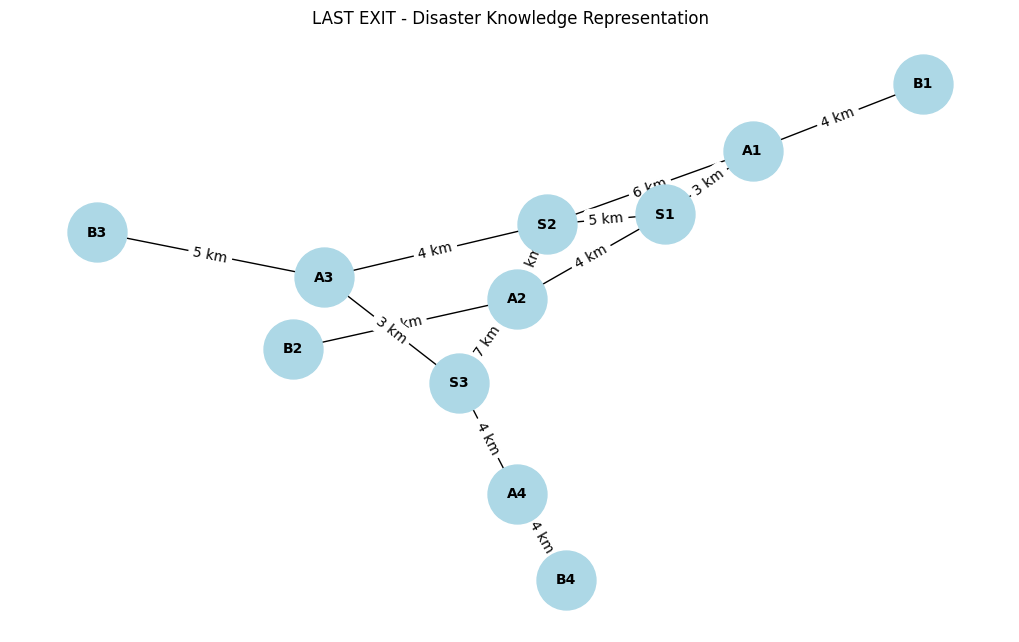

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G, pos,
    with_labels=True,
    node_size=1800,
    node_color="lightblue",
    font_size=10,
    font_weight="bold"
)

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels={
        (u, v): f"{d['distance']} km"
        for u, v, d in G.edges(data=True)
    }
)

plt.title("LAST EXIT - Disaster Knowledge Representation")
plt.show()

# 2. Rule-Based Reasoning

In [29]:

def evacuation_rules(area):
    facts = []
    rules_triggered = []

    # Rule 1: Identify critical flooding
    if area["flood"] >= 8:
        facts.append("CRITICAL FLOOD")
        rules_triggered.append("R1: IF flood >= 8 THEN critical flood")

    # Rule 2: Identify high flooding
    if area["flood"] >= 6:
        facts.append("HIGH FLOOD")
        rules_triggered.append("R2: IF flood >= 6 THEN high flood")

    # Rule 3: Identify high population
    if area["people"] >= 50:
        facts.append("HIGH POPULATION")
        rules_triggered.append("R3: IF population >= 50 THEN high population")

    # Rule 4: Identify dangerous roads
    if area["road"] >= 7:
        facts.append("DANGEROUS ROAD")
        rules_triggered.append("R4: IF road >= 7 THEN dangerous road")

    # Rule 5: Determine evacuation priority
    if area["flood"] >= 8 and area["people"] >= 50:
        priority = "CRITICAL"
        rules_triggered.append("R5: IF critical flood AND high population THEN critical priority")

    elif area["flood"] >= 6 or area["road"] >= 7:
        priority = "HIGH"
        rules_triggered.append("R6: IF high flood OR dangerous road THEN high priority")

    else:
        priority = "NORMAL"
        rules_triggered.append("R7: IF no critical condition THEN normal priority")

    # Rule 6: Recommend rescue action
    if priority == "CRITICAL":
        action = "Immediate evacuation and priority rescue deployment"

    elif priority == "HIGH":
        action = "Deploy rescue team and prepare nearby shelter"

    else:
        action = "Monitor conditions and keep rescue team on standby"

    return priority, facts, rules_triggered, action


# Forward chaining for all affected areas
for area_id, data in areas.items():

    priority, facts, rules, action = evacuation_rules(data)

    print("=" * 50)
    print("Affected Area:", area_id, "-", data["name"])
    print("Population:", data["people"])
    print("Flood Level:", data["flood"])
    print("Road Condition:", data["road"])

    print("\nIdentified Facts:", facts)

    print("\nRules Triggered:")
    for rule in rules:
        print("-", rule)

    print("\nEvacuation Priority:", priority)
    print("Recommended Action:", action)
    print()


Affected Area: A1 - Riverside
Population: 80
Flood Level: 9
Road Condition: 7

Identified Facts: ['CRITICAL FLOOD', 'HIGH FLOOD', 'HIGH POPULATION', 'DANGEROUS ROAD']

Rules Triggered:
- R1: IF flood >= 8 THEN critical flood
- R2: IF flood >= 6 THEN high flood
- R3: IF population >= 50 THEN high population
- R4: IF road >= 7 THEN dangerous road
- R5: IF critical flood AND high population THEN critical priority

Evacuation Priority: CRITICAL
Recommended Action: Immediate evacuation and priority rescue deployment

Affected Area: A2 - City Center
Population: 55
Flood Level: 7
Road Condition: 5

Identified Facts: ['HIGH FLOOD', 'HIGH POPULATION']

Rules Triggered:
- R2: IF flood >= 6 THEN high flood
- R3: IF population >= 50 THEN high population
- R6: IF high flood OR dangerous road THEN high priority

Evacuation Priority: HIGH
Recommended Action: Deploy rescue team and prepare nearby shelter

Affected Area: A3 - Village
Population: 40
Flood Level: 5
Road Condition: 3

Identified Facts: []

# 3. Handling Uncertainty Using Fuzzy Logic

In [30]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

flood = ctrl.Antecedent(np.arange(0, 11, 1), "flood")
road = ctrl.Antecedent(np.arange(0, 11, 1), "road")
priority = ctrl.Consequent(np.arange(0, 101, 1), "priority")

# Membership functions
flood["low"] = fuzz.trimf(flood.universe, [0, 0, 5])
flood["medium"] = fuzz.trimf(flood.universe, [2, 5, 8])
flood["high"] = fuzz.trimf(flood.universe, [5, 10, 10])

road["good"] = fuzz.trimf(road.universe, [0, 0, 4])
road["moderate"] = fuzz.trimf(road.universe, [2, 5, 8])
road["poor"] = fuzz.trimf(road.universe, [6, 10, 10])

priority["low"] = fuzz.trimf(priority.universe, [0, 0, 40])
priority["medium"] = fuzz.trimf(priority.universe, [25, 50, 75])
priority["high"] = fuzz.trimf(priority.universe, [60, 100, 100])

print("Fuzzy membership functions created.")

Fuzzy membership functions created.


In [31]:
rules = [
    ctrl.Rule(flood["high"], priority["high"]),
    ctrl.Rule(road["poor"], priority["high"]),
    ctrl.Rule(flood["medium"] & road["moderate"], priority["medium"]),
    ctrl.Rule(flood["low"] & road["good"], priority["low"]),
    ctrl.Rule(flood["high"] & road["poor"], priority["high"])
]

evacuation_system = ctrl.ControlSystem(rules)

def fuzzy_priority(flood_level, road_level):
    simulation = ctrl.ControlSystemSimulation(evacuation_system)

    simulation.input["flood"] = flood_level
    simulation.input["road"] = road_level

    simulation.compute()

    return round(simulation.output["priority"], 2)


for area_id, data in areas.items():
    score = fuzzy_priority(data["flood"], data["road"])
    print(area_id, "Fuzzy Priority:", score)

A1 Fuzzy Priority: 86.22
A2 Fuzzy Priority: 66.01
A3 Fuzzy Priority: 50.0
A4 Fuzzy Priority: 16.33


# 4. Resource Allocation

In [32]:
def find_shelter(area_id, graph, available_shelters,
                 required_people=1):

    candidates = []

    for shelter_id, capacity in available_shelters.items():

        if capacity <= 0:
            continue

        try:
            distance = nx.shortest_path_length(
                graph, area_id, shelter_id, weight="weight"
            )

            # Prefer shelters with sufficient capacity
            insufficient = capacity < required_people

            candidates.append(
                (shelter_id, distance, insufficient)
            )

        except nx.NetworkXNoPath:
            continue

    if not candidates:
        return None

    candidates.sort(key=lambda x: (x[2], x[1]))

    return candidates[0][0]


print("Capacity-aware shelter selection ready.")

Capacity-aware shelter selection ready.


In [33]:
def prepare_network(blocked_edges=None):
    graph = G.copy()

    blocked_edges = blocked_edges or []

    for u, v in blocked_edges:
        if graph.has_edge(u, v):
            graph.remove_edge(u, v)

    for u, v, data in graph.edges(data=True):
        distance = data["distance"]
        condition = data["condition"]

        data["weight"] = distance * (1 + condition * 0.15)

    return graph


normal_graph = prepare_network()

print("Normal road network ready.")
print("Available roads:", normal_graph.number_of_edges())

Normal road network ready.
Available roads: 13


# 5. Multi-Agent Coordination using CNP

In [34]:
def contract_net(area_id, graph, available_teams):
    bids = []

    for team_id in available_teams:
        base = teams[team_id]["base"]

        try:
            distance = nx.shortest_path_length(
                graph, base, area_id, weight="weight"
            )

            speed = teams[team_id]["speed"]
            travel_time = distance / speed * 60

            capacity = teams[team_id]["capacity"]

            bid = travel_time + max(
                0, areas[area_id]["people"] - capacity
            ) * 0.5

            bids.append((team_id, bid))

        except nx.NetworkXNoPath:
            continue

    if not bids:
        return None, []

    bids.sort(key=lambda x: x[1])

    winner = bids[0][0]

    return winner, bids


print("Contract Net Protocol initialized.")

Contract Net Protocol initialized.


# 6. Simulation and Evaluation

In [35]:

# Connect rescue team bases
base_roads = [
    ("B1", "B2", 5, 2),
    ("B2", "B3", 6, 3),
    ("B3", "B4", 4, 2)
]

for u, v, distance, condition in base_roads:
    G.add_edge(
        u, v,
        distance=distance,
        condition=condition
    )


def run_simulation(scenario, blocked_edges=None,
                   unavailable_shelters=None):

    graph = prepare_network(blocked_edges)

    remaining_capacity = {
        sid: data["capacity"]
        for sid, data in shelters.items()
        if sid not in (unavailable_shelters or [])
    }

    available_teams = list(teams.keys())
    results = []
    total_time = 0

    # Calculate fuzzy priorities
    priorities = {
        aid: fuzzy_priority(data["flood"], data["road"])
        for aid, data in areas.items()
    }

    # Process highest-priority areas first
    ordered_areas = sorted(
        areas.keys(),
        key=lambda x: priorities[x],
        reverse=True
    )

    for area_id in ordered_areas:

        # CNP: Task announcement and bidding
        team_id, bids = contract_net(
            area_id, graph, available_teams
        )

        print(f"\nTask Announcement: {area_id}")
        print("Team Bids:", bids)

        if team_id is None:
            print("No available rescue team.")
            continue

        print("Contract Awarded To:", team_id)

        # Calculate evacuation capacity
        people = areas[area_id]["people"]
        team_capacity = teams[team_id]["capacity"]

        required_people = min(people, team_capacity)

        # Find a suitable shelter with available capacity
        shelter_id = find_shelter(
            area_id, graph, remaining_capacity,
            required_people
        )

        if shelter_id is None:
            print("No reachable shelter available.")
            continue

        evacuated = min(
            people,
            team_capacity,
            remaining_capacity[shelter_id]
        )

        if evacuated <= 0:
            continue

        # Calculate travel time
        base = teams[team_id]["base"]
        speed = teams[team_id]["speed"]

        distance1 = nx.shortest_path_length(
            graph, base, area_id, weight="weight"
        )

        distance2 = nx.shortest_path_length(
            graph, area_id, shelter_id, weight="weight"
        )

        travel_time = (
            (distance1 + distance2) / speed
        ) * 60 + 10

        total_time = max(total_time, travel_time)

        # Update resources
        remaining_capacity[shelter_id] -= evacuated
        available_teams.remove(team_id)

        results.append({
            "Area": area_id,
            "Team": team_id,
            "Shelter": shelter_id,
            "Priority": priorities[area_id],
            "People": people,
            "Evacuated": evacuated,
            "Travel Time (min)": round(travel_time, 2)
        })

        print(
            f"Evacuated {evacuated} people from "
            f"{area_id} to {shelter_id}"
        )

    # Calculate final performance
    total_people = sum(
        data["people"] for data in areas.values()
    )

    safe_people = sum(
        result["Evacuated"] for result in results
    )

    used_capacity = sum(
        teams[result["Team"]]["capacity"]
        for result in results
    )

    utilization = (
        safe_people / used_capacity * 100
        if used_capacity > 0 else 0
    )

    return {
        "Scenario": scenario,
        "Details": results,
        "Evacuated": safe_people,
        "Remaining": total_people - safe_people,
        "Evacuation Time": round(total_time, 2),
        "Teams Used": len(results),
        "Utilization": round(utilization, 2)
    }


print("Updated evacuation simulation function created.")


Updated evacuation simulation function created.


In [36]:
normal_result = run_simulation(
    "Normal Scenario"
)

unexpected_result = run_simulation(
    "Unexpected Scenario",
    blocked_edges=[("A2", "S1")],
    unavailable_shelters=["S2"]
)

print("NORMAL SCENARIO")
print("People Evacuated:", normal_result["Evacuated"])
print("Remaining People:", normal_result["Remaining"])
print("Evacuation Time:", normal_result["Evacuation Time"], "minutes")

print("\nUNEXPECTED SCENARIO")
print("People Evacuated:", unexpected_result["Evacuated"])
print("Remaining People:", unexpected_result["Remaining"])
print("Evacuation Time:", unexpected_result["Evacuation Time"], "minutes")


Task Announcement: A1
Team Bids: [('T1', 17.8), ('T2', 35.05714285714285), ('T4', 54.13333333333333), ('T3', 58.3)]
Contract Awarded To: T1
Evacuated 60 people from A1 to S1

Task Announcement: A2
Team Bids: [('T2', 9.957142857142856), ('T3', 31.099999999999998), ('T4', 31.833333333333332)]
Contract Awarded To: T2
Evacuated 50 people from A2 to S2

Task Announcement: A3
Team Bids: [('T3', 13.0), ('T4', 15.600000000000001)]
Contract Awarded To: T3
Evacuated 40 people from A3 to S3

Task Announcement: A4
Team Bids: [('T4', 6.133333333333333)]
Contract Awarded To: T4
Evacuated 30 people from A4 to S3

Task Announcement: A1
Team Bids: [('T1', 17.8), ('T2', 35.05714285714285), ('T4', 54.13333333333333), ('T3', 58.3)]
Contract Awarded To: T1
Evacuated 60 people from A1 to S1

Task Announcement: A2
Team Bids: [('T2', 9.957142857142856), ('T3', 31.099999999999998), ('T4', 31.833333333333332)]
Contract Awarded To: T2
Evacuated 50 people from A2 to S3

Task Announcement: A3
Team Bids: [('T3', 1

In [37]:
import pandas as pd

normal_df = pd.DataFrame(normal_result["Details"])
unexpected_df = pd.DataFrame(unexpected_result["Details"])

print("NORMAL SCENARIO ASSIGNMENTS")
display(normal_df)

print("UNEXPECTED SCENARIO ASSIGNMENTS")
display(unexpected_df)

NORMAL SCENARIO ASSIGNMENTS


,Area,Team,Shelter,Priority,People,Evacuated,Travel Time (min)
0,A1,T1,S1,86.22,80,60,24.33
1,A2,T2,S2,66.01,55,50,25.69
2,A3,T3,S3,50.00,40,40,31.70
3,A4,T4,S3,16.33,30,30,22.27


UNEXPECTED SCENARIO ASSIGNMENTS


,Area,Team,Shelter,Priority,People,Evacuated,Travel Time (min)
0,A1,T1,S1,86.22,80,60,24.33
1,A2,T2,S3,66.01,55,50,33.06
2,A3,T3,S1,50.00,40,40,46.40
3,A4,T4,S3,16.33,30,30,22.27


In [38]:
comparison = pd.DataFrame([
    {
        "Scenario": normal_result["Scenario"],
        "People Evacuated": normal_result["Evacuated"],
        "People Remaining": normal_result["Remaining"],
        "Evacuation Time": normal_result["Evacuation Time"],
        "Teams Used": normal_result["Teams Used"],
        "Resource Utilization (%)": normal_result["Utilization"]
    },
    {
        "Scenario": unexpected_result["Scenario"],
        "People Evacuated": unexpected_result["Evacuated"],
        "People Remaining": unexpected_result["Remaining"],
        "Evacuation Time": unexpected_result["Evacuation Time"],
        "Teams Used": unexpected_result["Teams Used"],
        "Resource Utilization (%)": unexpected_result["Utilization"]
    }
])

display(comparison)

,Scenario,People Evacuated,People Remaining,Evacuation Time,Teams Used,Resource Utilization (%)
0,Normal Scenario,180,25,31.7,4,92.31
1,Unexpected Scenario,180,25,46.4,4,92.31


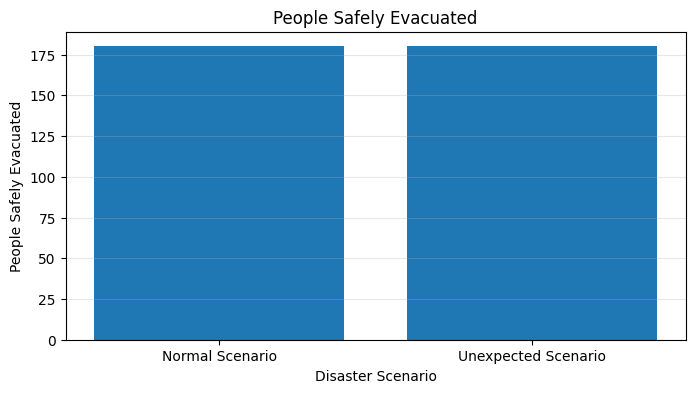

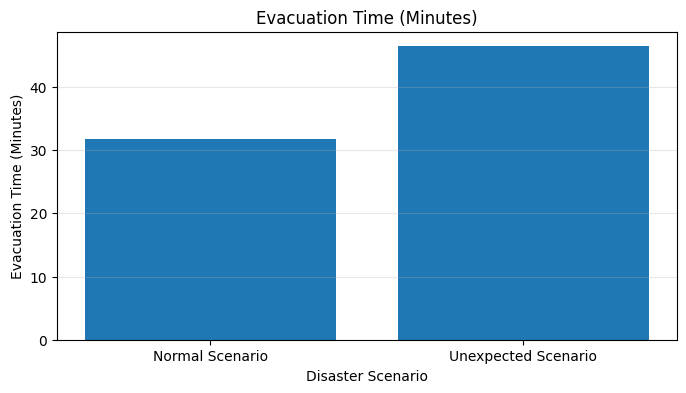

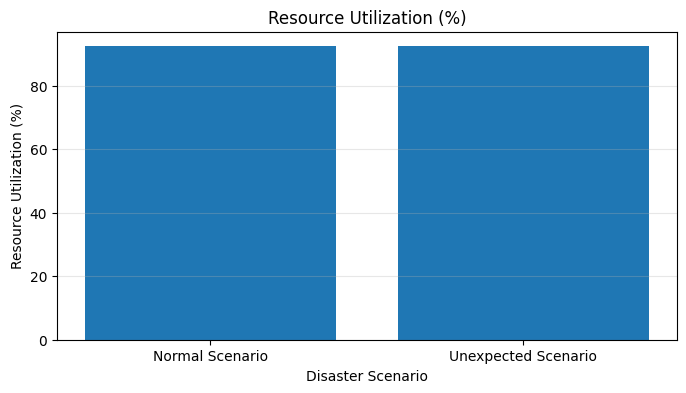

In [39]:
metrics = [
    ("People Evacuated", "People Safely Evacuated"),
    ("Evacuation Time", "Evacuation Time (Minutes)"),
    ("Resource Utilization (%)", "Resource Utilization (%)")
]

for column, title in metrics:

    plt.figure(figsize=(8, 4))

    plt.bar(
        comparison["Scenario"],
        comparison[column]
    )

    plt.title(title)
    plt.ylabel(title)
    plt.xlabel("Disaster Scenario")
    plt.grid(axis="y", alpha=0.3)

    plt.show()

In [40]:
!pip install -q networkx scikit-fuzzy numpy pandas matplotlib seaborn

In [41]:
import numpy as np
import pandas as pd
import networkx as nx
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully.")

All libraries imported successfully.


In [42]:
print("=" * 50)
print("PROJECT LAST EXIT - FINAL REPORT")
print("=" * 50)

for result in [normal_result, unexpected_result]:

    print("\nScenario:", result["Scenario"])
    print("Successfully Evacuated:", result["Evacuated"])
    print("People Remaining:", result["Remaining"])
    print("Teams Deployed:", result["Teams Used"])
    print("Evacuation Time:", result["Evacuation Time"], "minutes")
    print("Resource Utilization:", result["Utilization"], "%")

print("\nExperiment completed successfully.")

PROJECT LAST EXIT - FINAL REPORT

Scenario: Normal Scenario
Successfully Evacuated: 180
People Remaining: 25
Teams Deployed: 4
Evacuation Time: 31.7 minutes
Resource Utilization: 92.31 %

Scenario: Unexpected Scenario
Successfully Evacuated: 180
People Remaining: 25
Teams Deployed: 4
Evacuation Time: 46.4 minutes
Resource Utilization: 92.31 %

Experiment completed successfully.
